# Task 3: Critical Moment and Conditional Prediction

The eight figures are shown in this notebook as saved images (also stored in
`figures/`), so they can be read on GitHub, in VS Code or in Jupyter without
running code. The images show the saved
primary scenario. Use Section 3.5 for the interactive browser dashboard.

To rerun the analysis cells, place this notebook in the original project folder,
select its Python environment, and choose Run All. The default reads the saved
result files. Set RECOMPUTE = True in the setup cell only for a full model refit.


In [1]:
from IPython.display import display, Markdown
display(Markdown('The figures are embedded below as static images. No HTML iframe or Plotly renderer is required to read them.'))

The figures are embedded below as static images. No HTML iframe or Plotly renderer is required to read them.

## 3. Critical Moment and Conditional Prediction

G1 (cool hours with high NOx) was found visually in Task 1 by lassoing a dense band in the T vs NOx scatterplot. Because that lasso boundary was not saved, this analysis fixes the visually observed boundary as a reproducible reference group, G1-A (T ≤ 12°C and NOx ≥ 250 ppb). The thresholds were read off the Task 1 scatterplot, not computed by any algorithm. G1-A represents the cool, high-NOx pattern identified in the similarity analysis and includes 983 complete hourly observations. The earlier interactive selection contained 966 observations, but its selection boundaries were not saved. G1-A therefore provides a reproducible reference for this analysis rather than an exact reconstruction of the earlier selection. The same nine numerical attributes and DateTime are used throughout. Missing values are not filled, and no clustering is used.

The selected case is 11 November 2004 at 20:00. Three models predict that the observation remains in G1-A when temperature is reduced by 2°C and relative humidity is unchanged. The analysis concerns this single hour. Earlier R1 results are saved in output/task3/stage3.

**Link to Task 2.** Task 2 shows that the traffic group switches from a benzene-led to a NOx-led profile between September and November 2004, and the day-level t-SNE view places the sharpest break between 6 and 7 November 2004, when a cold front arrived. The 11 November case examined here sits inside that new cold-season regime: it is an hour-level example of how close cold-season hours are to the edge of G1, where a rise of under 1°C is enough to leave the group.

**Environment setup (only if needed)**

Open the complete project folder in VS Code and select the Python kernel where
the project requirements are installed. No installation is needed simply to
read the saved figures and tables.

If a package is missing when running code, run the following in a new notebook
cell from the project folder, then restart the kernel:

```python
%pip install -r requirements.txt
```

The requirements path is relative to the project; it is not tied to a particular
student's computer.

In [ ]:
# Read saved results by default. A full refit includes 80 bootstrap fits.
RECOMPUTE = False
# Optional: enter the original project folder if automatic detection fails.
PROJECT_FOLDER = None

import os
import sys
import json
from pathlib import Path
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[name] = '1'

here = Path.cwd().resolve()
candidates = [Path(PROJECT_FOLDER).expanduser().resolve()] if PROJECT_FOLDER else []
if not PROJECT_FOLDER:
    for parent in [here, *here.parents]:
        candidates.extend([parent, parent / 'MemberA_Student_Code_EN', parent / 'MemberA_5048'])
ROOT = next((p for p in candidates if (p / 'run_analysis.py').is_file()
             and (p / 'output/task3/stage4/G1A_results.json').is_file()), None)
DATA_AVAILABLE = ROOT is not None
if not DATA_AVAILABLE:
    print('Project data folder not found: the figures and saved tables below are still readable.\n'
          'To rerun the data cells, open this notebook inside the Task 3 project folder '
          '(with run_analysis.py and output/) or set PROJECT_FOLDER above.')
else:
    os.chdir(ROOT)
if DATA_AVAILABLE:
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    try:
        import pandas as pd
        from IPython.display import display, Markdown
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            'Install the requirements in the selected kernel with %pip install -r requirements.txt, '
            'then restart the kernel and Run All.'
        ) from exc
    OUT = ROOT / 'output/task3/stage4'
    if RECOMPUTE:
        from scripts.run_member_a_stage4 import run
        print('Full model and bootstrap recomputation requested. This may take several minutes.', flush=True)
        results = run(recompute=True)
    else:
        results = json.loads((OUT / 'G1A_results.json').read_text(encoding='utf-8'))
    print('Mode:', 'full recomputation' if RECOMPUTE else 'saved results; no model fitting required')
    print('Current model:', results['selected_model'])
    print('One-hour conditional scope:', results['condition'])
    if RECOMPUTE:
        print('The embedded images remain the saved primary-scenario snapshots. Inspect the regenerated dashboard if inputs or methods were changed.')


Project data folder not found: the figures and saved tables below are still readable.
To rerun the data cells, open this notebook inside the Task 3 project folder (with run_analysis.py and output/) or set PROJECT_FOLDER above.


### 3.1 Identifying the Critical Moment

The scatterplot, time series, and parallel coordinates show how the observation crosses the group boundary. At 19:00, T = 12.0°C and NOx = 463 ppb, so the observation belongs to G1-A. At 20:00, T rises to 12.9°C and NOx reaches 568 ppb. The observation leaves the group because temperature exceeds 12°C, even though NOx increases.

In [ ]:
if DATA_AVAILABLE:
    members = pd.read_csv(OUT/'G1A_all_memberships.csv', parse_dates=['DateTime'])
    display(members.G1A_member.value_counts())
    display(members[members.DateTime.between('2004-11-11 18:00','2004-11-11 21:00')])

G1A_member
False    5958
True      983
Name: count, dtype: int64

,row_id,DateTime,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH,G1A_member
4020,5904,2004-11-11 18:00:00,3.9,1201.0,16.5,1196.0,573.0,187.0,11.6,76.0,1.0354,True
4021,5905,2004-11-11 19:00:00,3.5,1189.0,16.1,1183.0,463.0,166.0,12.0,73.3,1.0264,True
4022,5906,2004-11-11 20:00:00,4.7,1282.0,20.6,1312.0,568.0,177.0,12.9,68.8,1.0175,False
4023,5907,2004-11-11 21:00:00,4.6,1207.0,16.8,1203.0,706.0,207.0,13.1,69.6,1.0464,False


#### Figure 1. Observed hourly transition


The event line marks 11 November 2004 at 20:00. Missing observations remain gaps.

*Saved primary-scenario image; this figure is not interactive.*

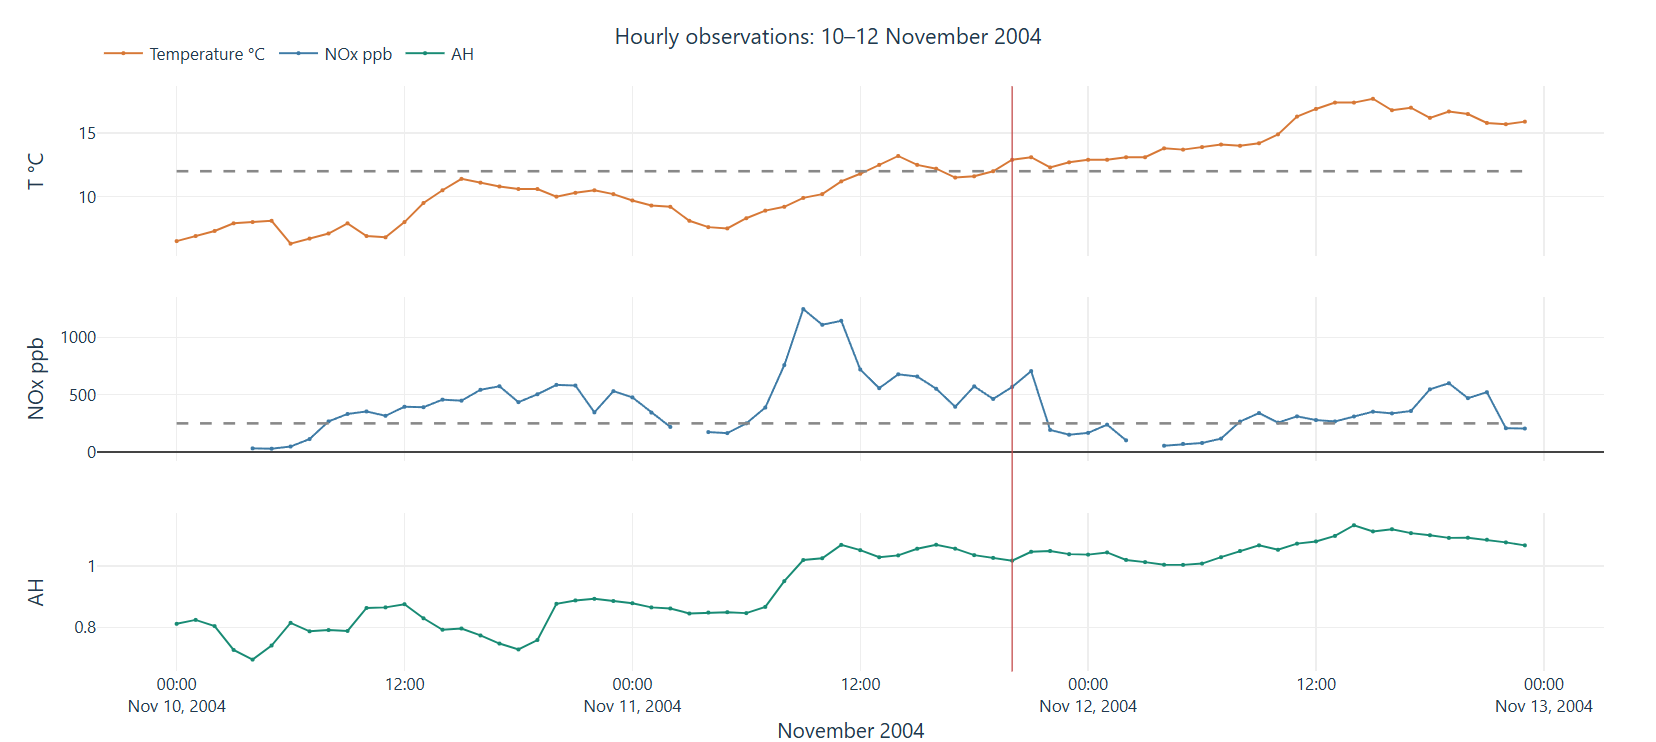

In [ ]:
from IPython.display import Image
Image(filename='figures/timeline.png')

#### Figure 2. The operational G1-A group


The declared boundary identifies 983 of 6,941 complete hours. This image is static; brushing is available in the browser dashboard.

*Saved primary-scenario image; this figure is not interactive.*

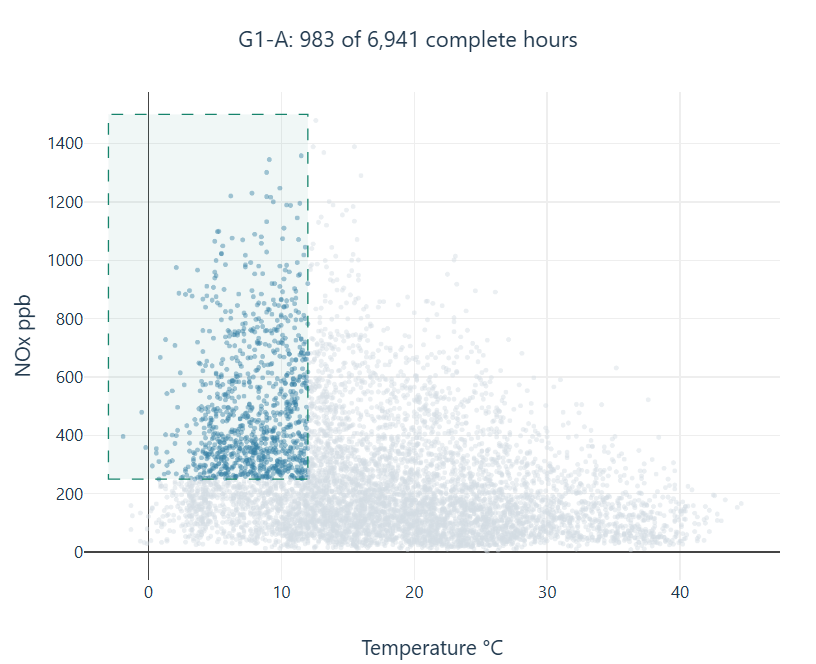

In [ ]:
from IPython.display import Image
Image(filename='figures/discovery.png')

### 3.2 Regression Model and Validation

The models use observations from one and two hours earlier to predict changes in six response variables. Six weather and history models are compared using four forward calendar folds. Final training ends on 29 October.

The case occurs after the training period, but the benchmark dates had already been inspected. The evaluation therefore uses temporal separation without a fully unseen test case.

In [ ]:
if DATA_AVAILABLE:
    display(pd.read_csv(OUT/'dynamic_fold_ranges.csv'))
    display(pd.read_csv(OUT/'dynamic_ranking.csv'))
    validation = pd.read_csv(OUT/'G1A_validation.csv')
    display(validation[validation.model == results['selected_model']])

,fold,train_n,train_end,valid_start,valid_end,valid_n
0,jul,1826,2004-06-29 23:00:00,2004-07-01 00:00:00,2004-07-31 23:00:00,481
1,aug,2311,2004-07-26 02:00:00,2004-08-01 00:00:00,2004-08-31 23:00:00,361
2,sep,2682,2004-08-28 13:00:00,2004-09-01 00:00:00,2004-09-30 23:00:00,388
3,oct,3067,2004-09-29 23:00:00,2004-10-01 00:00:00,2004-10-28 23:00:00,270


,model,cv_profile_mae
0,weather_extra,0.178891
1,history_extra,0.179564
2,weather_hgb,0.180679
3,history_hgb,0.183647
4,persistence,0.214286
5,history_ridge,0.230484
6,weather_ridge,0.230495


,model,split,n,tn,fp,fn,tp,accuracy,r2,mae,residual_interval_coverage
12,weather_extra,event_after,116,83,1,3,29,0.965517,0.742442,76.856319,0.750000
13,weather_extra,event_before,133,133,0,0,0,1.000000,0.632661,78.903124,0.744361
14,weather_extra,reused_jan_apr,1522,960,70,57,435,0.916557,0.792460,61.641929,0.822602


#### Figure 3. Observed and one-step predicted NOx


This comparison assesses predictions under observed conditions, not the causal effect of changing weather.

*Saved primary-scenario image; this figure is not interactive.*

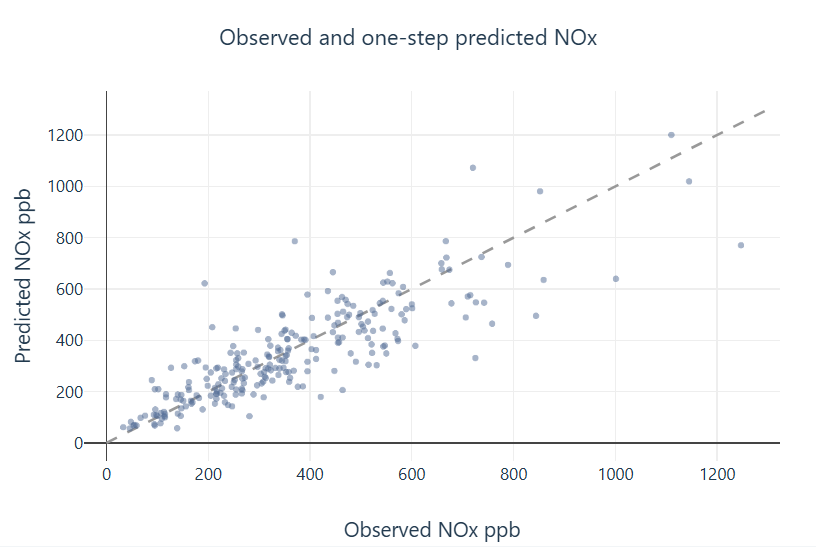

In [ ]:
from IPython.display import Image
Image(filename='figures/validation.png')

### 3.3 Temperature Scenario

Temperature is reduced by 2°C, while relative humidity and the previous two observed hours remain fixed. Absolute humidity is calculated using the relationship fitted to the training data. All six responses are predicted again without adding the current observation's residual.

The 13:00 case is included for comparison, but one of its lagged inputs lies outside the supported range.

In [ ]:
if DATA_AVAILABLE:
    scenarios = pd.read_csv(OUT/'G1A_all_fixed_scenarios.csv', parse_dates=['DateTime'])
    primary = scenarios[(scenarios.DateTime == '2004-11-11 20:00') &
                        (scenarios.scenario == 'cooler_2C_fixed_RH') &
                        scenarios.model.str.startswith('weather_')]
    display(primary[['model','T','RH','AH','NOx(GT)','predicted_G1A',
                     'weather_supported','lag_context_in_range']])
    display(pd.DataFrame(results['cases']))

,model,T,RH,AH,NOx(GT),predicted_G1A,weather_supported,lag_context_in_range
794,weather_ridge,10.9,68.8,0.894078,432.707584,True,True,True
836,weather_hgb,10.9,68.8,0.894078,344.631585,True,True,True
878,weather_extra,10.9,68.8,0.894078,428.202488,True,True,True


,time,checks,passes_all_initial_checks,actual_T,actual_NOx,altered_T,altered_RH,altered_AH,predicted_NOx,lower90,upper90,out_of_range_lags,family_predictions
0,2004-11-11 13:00:00,"{'factual_exit_correct': True, 'all_weather_fa...",False,12.5,557.0,10.5,71.3,0.903412,661.923586,560.074906,763.772266,lag2_NOx(GT),"{'weather_ridge': 597.0203125706042, 'weather_..."
1,2004-11-11 20:00:00,"{'factual_exit_correct': True, 'all_weather_fa...",True,12.9,568.0,10.9,68.8,0.894078,428.202488,326.353807,530.051168,,"{'weather_ridge': 432.70758429593525, 'weather..."


#### Figure 4. Observed and predicted group positions


The saved primary scenario changes temperature by -2 degrees Celsius while keeping RH fixed.

*Saved primary-scenario image; this figure is not interactive.*

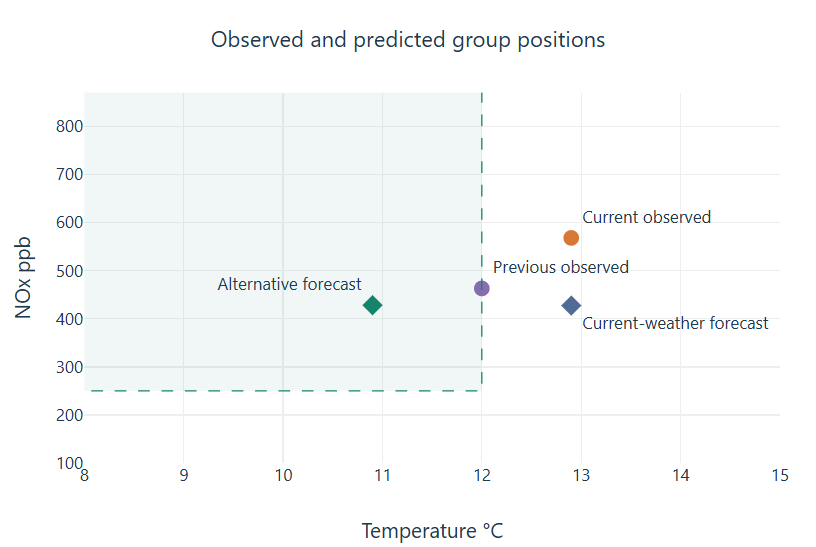

In [ ]:
from IPython.display import Image
Image(filename='figures/caseScatter.png')

#### Figure 5. NOx predictions from three weather models


All three point predictions exceed the 250 ppb group threshold for the saved primary scenario.

*Saved primary-scenario image; this figure is not interactive.*

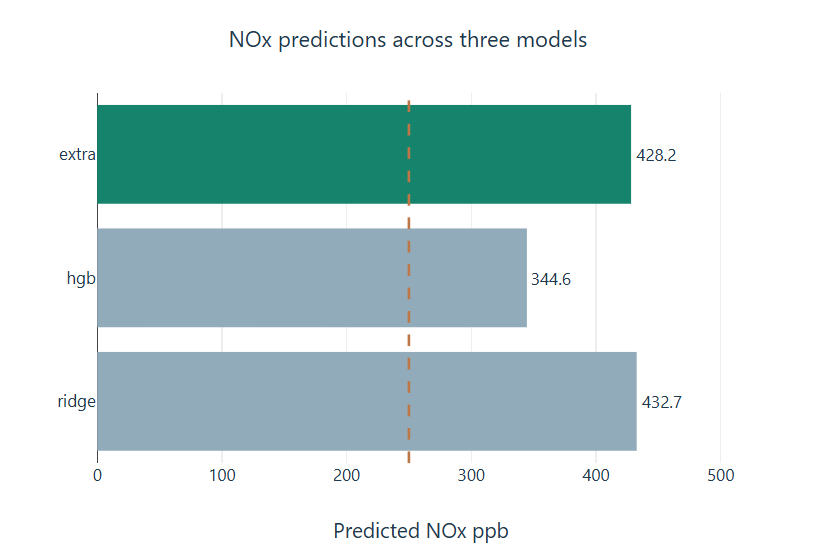

In [ ]:
from IPython.display import Image
Image(filename='figures/models.png')

#### Figure 6. Nine-attribute comparison


The four lines compare the previous observation, current observation, current-weather forecast and alternative forecast using training median/IQR scaling.

*Saved primary-scenario image; this figure is not interactive.*

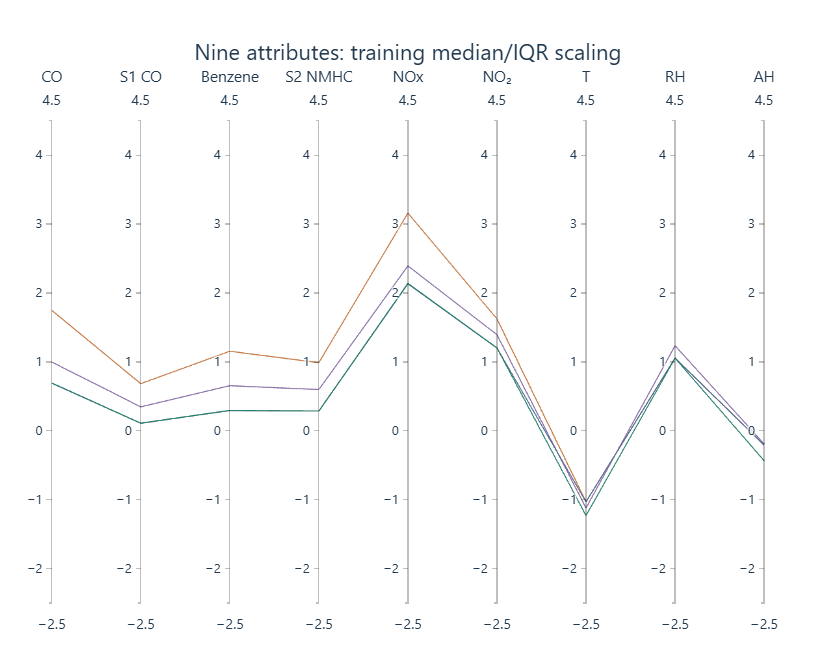

In [ ]:
from IPython.display import Image
Image(filename='figures/parallel.png')

Additional scenarios were examined using the precomputed ΔT × ΔAH grid. For the 20:00 case, the combinations below pass the physical, historical weather and lag-range checks. All three weather models predict G1-A membership for these combinations.

| ΔT (°C) | ΔAH (dataset units) | Derived RH (%) | Models predicting G1-A membership |
|---|---|---|---|
| −1.0 | −0.05 | 69.8 | 3/3 |
| −1.0 | 0.00 | 73.4 | 3/3 |
| −1.0 | +0.05 | 77.0 | 3/3 |
| −1.5 | 0.00 | 75.8 | 3/3 |

In these scenarios, T and AH are adjusted and RH is derived using the fitted humidity relationship. The combinations therefore differ from the primary fixed-RH scenario. The alternative-changes map shows their positions relative to the membership boundary and the limits of historical support.

These results identify several supported combinations that retain predicted threshold-group membership. Agreement across models does not establish a causal effect or guarantee preservation of the full pollutant profile.

#### Figure 7. Alternative changes and historical weather support


Green cells indicate predicted membership, orange cells indicate departure, and crosses mark weather outside historical support. The blue marker is the fixed-RH primary scenario.

*Saved primary-scenario image; this figure is not interactive.*

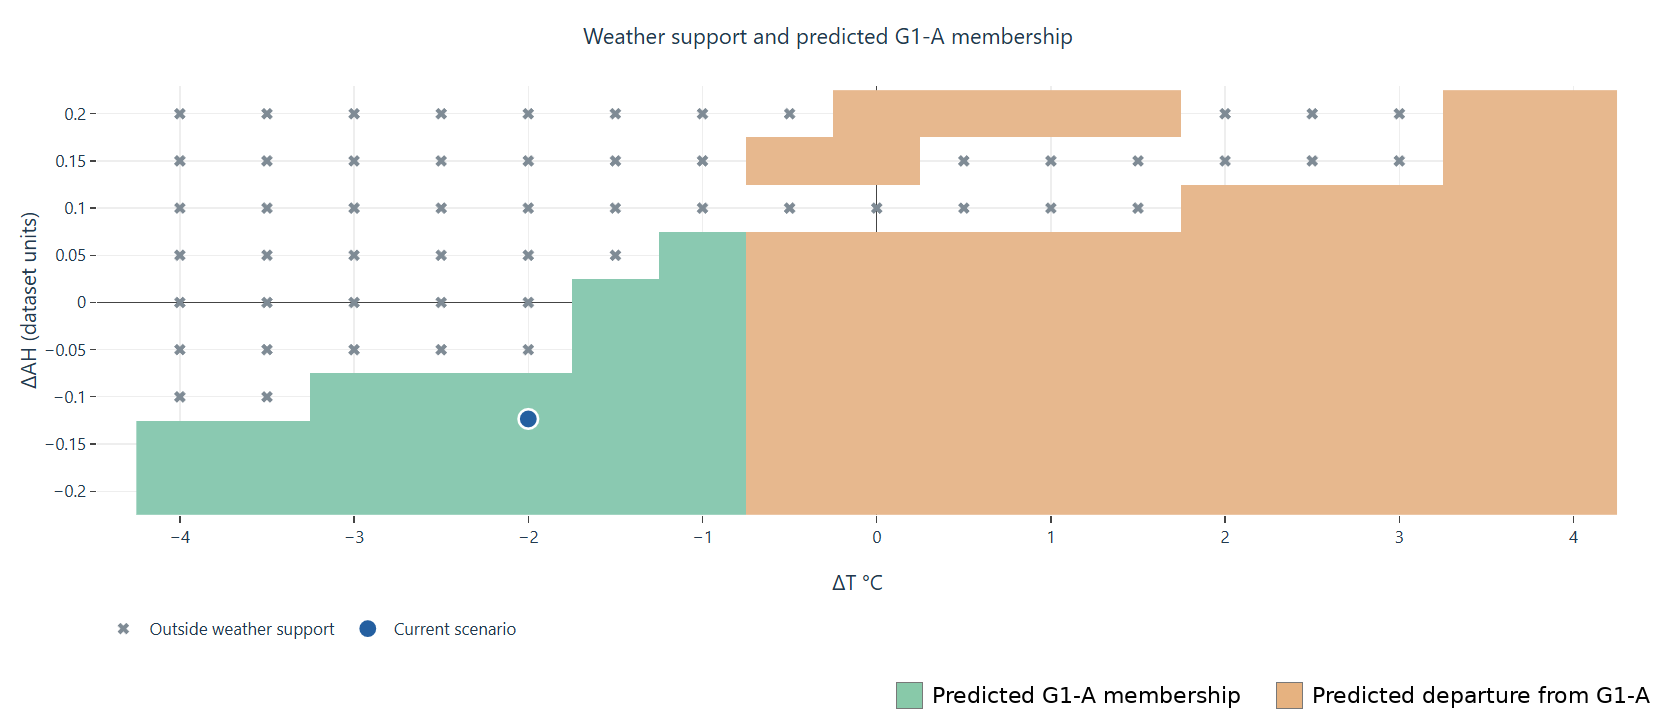

In [ ]:
from IPython.display import Image
Image(filename='figures/map.png')

### 3.4 Sensitivity and Uncertainty

The point-estimate result holds across 80 day-block bootstrap fits and nine nearby group-boundary definitions. However, the global 90% error interval covers only 75% of the post-event observations, and the high-NOx 95% interval crosses the group boundary. Group preservation is therefore supported by the point estimates, with uncertainty around the boundary. These intervals reflect prediction errors, not causal effects.

In [ ]:
if DATA_AVAILABLE:
    display(pd.read_csv(OUT/'G1A_bootstrap_summary.csv'))
    display(pd.read_csv(OUT/'G1A_boundary_sensitivity.csv'))
    display(pd.read_csv(OUT/'G1A_uncertainty_sensitivity.csv'))

,time,size,min,max,median,q05,q95
0,2004-11-11 13:00:00,80,640.031700,683.116287,665.940671,647.344038,679.472312
1,2004-11-11 20:00:00,80,401.422066,452.628198,427.177369,407.931611,439.148322


,time,T_cut,NOx_cut,observed_inside,factual_pred_inside,cooler_pred_inside,lower90_above_boundary
0,2004-11-11 13:00:00,11.5,225.0,False,False,True,True
1,2004-11-11 20:00:00,11.5,225.0,False,False,True,True
2,2004-11-11 13:00:00,11.5,250.0,False,False,True,True
3,2004-11-11 20:00:00,11.5,250.0,False,False,True,True
4,2004-11-11 13:00:00,11.5,275.0,False,False,True,True
5,2004-11-11 20:00:00,11.5,275.0,False,False,True,True
6,2004-11-11 13:00:00,12.0,225.0,False,False,True,True
7,2004-11-11 20:00:00,12.0,225.0,False,False,True,True
8,2004-11-11 13:00:00,12.0,250.0,False,False,True,True
9,2004-11-11 20:00:00,12.0,250.0,False,False,True,True


,calibration_subset,n,quantile,absolute_error_rank,case20_lower,case20_upper,lower_preserves_nox
0,all_1500,1500,0.90,101.848680,326.353807,530.051168,True
1,all_1500,1500,0.95,137.691417,290.511071,565.893905,True
2,forecast_NOx_at_least_250,441,0.90,172.749638,255.452850,600.952125,True
3,forecast_NOx_at_least_250,441,0.95,206.742523,221.459964,634.945011,False
4,cool_and_forecast_high,3,0.90,326.361326,101.841162,754.563814,False
5,cool_and_forecast_high,3,0.95,326.361326,101.841162,754.563814,False


#### Figure 8. Historical prediction-error references


The high-NOx 95% historical error band crosses 250 ppb. These references are not guarantees of intervention success.

*Saved primary-scenario image; this figure is not interactive.*

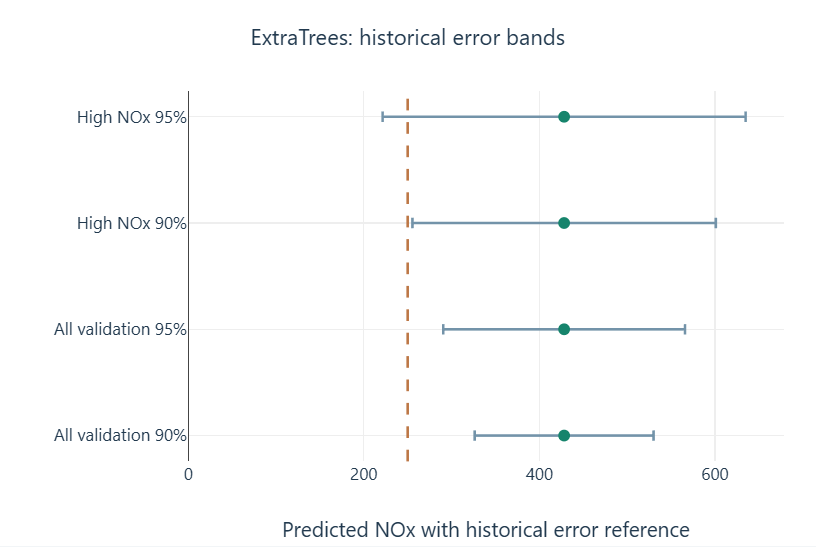

In [ ]:
from IPython.display import Image
Image(filename='figures/uncertainty.png')

### 3.5 Interactive Dashboard

The dashboard allows temperature, humidity constraints, models, and cases to be changed. Brushing selects the same observations across nine attributes. Selecting a point on the scenario map displays its predictions, and the three predicted rows can be downloaded. Combinations outside the supported range are marked in the dashboard.

The dashboard is also saved as an HTML file.

Open this HTML in a full web browser using the cell below. Set
OPEN_IN_BROWSER = True and run the cell. The browser opens on the computer
running the Python kernel; for a remote kernel, download the HTML and open it
locally. The embedded figures above remain available independently of the
interactive dashboard.


In [ ]:
if DATA_AVAILABLE:
    import webbrowser
    OPEN_IN_BROWSER = False
    dashboard = OUT / 'task3_dashboard.html'
    print('Interactive dashboard: output/task3/stage4/task3_dashboard.html')
    if OPEN_IN_BROWSER:
        if not dashboard.is_file():
            raise FileNotFoundError('Dashboard missing. Restore it from the full project package or rerun the analysis.')
        print('Browser launch requested:', webbrowser.open(dashboard.resolve().as_uri()))
    else:
        print('Set OPEN_IN_BROWSER = True and run this cell to open the interactive dashboard.')


Interactive dashboard: output/task3/stage4/task3_dashboard.html
Set OPEN_IN_BROWSER = True and run this cell to open the interactive dashboard.


### 3.6 Interpret and hand over
The models predict that the 20:00 observation satisfies the G1-A criteria when temperature is reduced by 2°C and relative humidity remains unchanged. Since temperature is part of the group definition, predicted re-entry partly follows directly from moving below the 12°C threshold.

The pollutant predictions provide additional evidence: predicted NOx remains above 250 ppb in all three weather models. The parallel coordinates compare the previous observation, current observation, current-weather prediction and alternative-weather prediction across all nine attributes. They show the accompanying changes in the other pollutants and sensor responses, but no preservation criteria were specified for those attributes.

The result therefore supports predicted membership in the threshold-defined group, rather than preservation of the full pollutant profile. It is a one-hour conditional prediction with the previous two observed hours held fixed, not evidence that lowering temperature would causally prevent the observed change.

In [ ]:
print('Run instructions: README.md')
print('Method and results: docs/METHOD_AND_RESULTS.md')
print('Student handover: docs/STUDENT_CHECKLIST.md')
print('Recompute: python run_analysis.py --recompute')

Run instructions: README.md
Method and results: docs/METHOD_AND_RESULTS.md
Student handover: docs/STUDENT_CHECKLIST.md
Recompute: python run_analysis.py --recompute


## 3.7 Findings

| Item | Value / evidence |
|---|---|
| Critical moment | 11 November 2004, 19:00–20:00; the temperature threshold is crossed while NOx remains high. This hour lies inside the cold-season regime that starts with the 6→7 November break found in Task 2 (t-SNE day view). |
| Before / after | Six-hour windows contain 6 complete observations each. Median T increases from 12.1 to 12.9°C; G1-A membership falls from 3/6 to 0/6. The window summary reports RH and AH alongside T. |
| Primary scenario | ΔT = −2°C at RH = 68.8%; all three weather models predict G1-A membership and pass weather and lag support checks. |
| Alternative combinations | The selected model has 24 supported membership-preserving ΔT × ΔAH grid cells. Examples include ΔT = −1°C with ΔAH = −0.05, 0, or +0.05; the dashboard reports derived RH and three-model agreement. |
| Pollutant evidence | Primary-case predicted NOx remains above 250 ppb in all three models. Parallel coordinates and the attribute table show the accompanying changes in all six responses. |
| Definition limit | The 983-observation threshold group differs from the earlier 966-point interactive selection; equivalence cannot be verified. |
| Prediction limit | Temperature is itself a membership criterion. Conditional predictions with fixed factual histories do not establish causal prevention or week-long preservation. |
| Uncertainty | Bootstrap and boundary checks support the point estimate, but residual-based intervals can cross the NOx boundary. 